In [1]:
!pip install -q easyocr pdf2image pymupdf Pillow matplotlib numpy

print("Installation complete.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 52.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.0/25.0 MB 63.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.6/299.6 kB 30.1 MB/s eta 0:00:00
Installation complete.


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import easyocr
import torch
import numpy as np


print(f"EasyOCR version: {easyocr.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

EasyOCR version: 1.7.2
CUDA available: True
GPU: Tesla T4


In [4]:
from google.colab import files
from pathlib import Path

TEST_DIR = Path("/content/drive/MyDrive/Data Legal/test")

pdf_files = sorted(TEST_DIR.glob("*.pdf"))
print(f"\nFiles: {len(pdf_files)}")
for f in pdf_files:
    print(f"  {f.name}")


Files: 4
  Livret 2.pdf
  code_route.pdf
  ظهير شريف رقم 1.10.07 صادر في 26 من صفر 1431 (11 فبراير 2010) بتنفيذ القانون رقم 52.05 المتعلق بمدونة السير على الطرق.pdf
  مدونة الأسرة1.pdf


Selecting previously unselected package poppler-utils.
(Reading database ... 122363 files and directories currently installed.)
Preparing to unpack .../poppler-utils_22.02.0-2ubuntu0.12_amd64.deb ...
Unpacking poppler-utils (22.02.0-2ubuntu0.12) ...
Setting up poppler-utils (22.02.0-2ubuntu0.12) ...
Processing triggers for man-db (2.10.2-1) ...
Converting: Livret 2.pdf
  2 pages
Converting: code_route.pdf
  2 pages
Converting: ظهير شريف رقم 1.10.07 صادر في 26 من صفر 1431 (11 فبراير 2010) بتنفيذ القانون رقم 52.05 المتعلق بمدونة السير على الطرق.pdf
  2 pages
Converting: مدونة الأسرة1.pdf
  2 pages

Total pages: 8


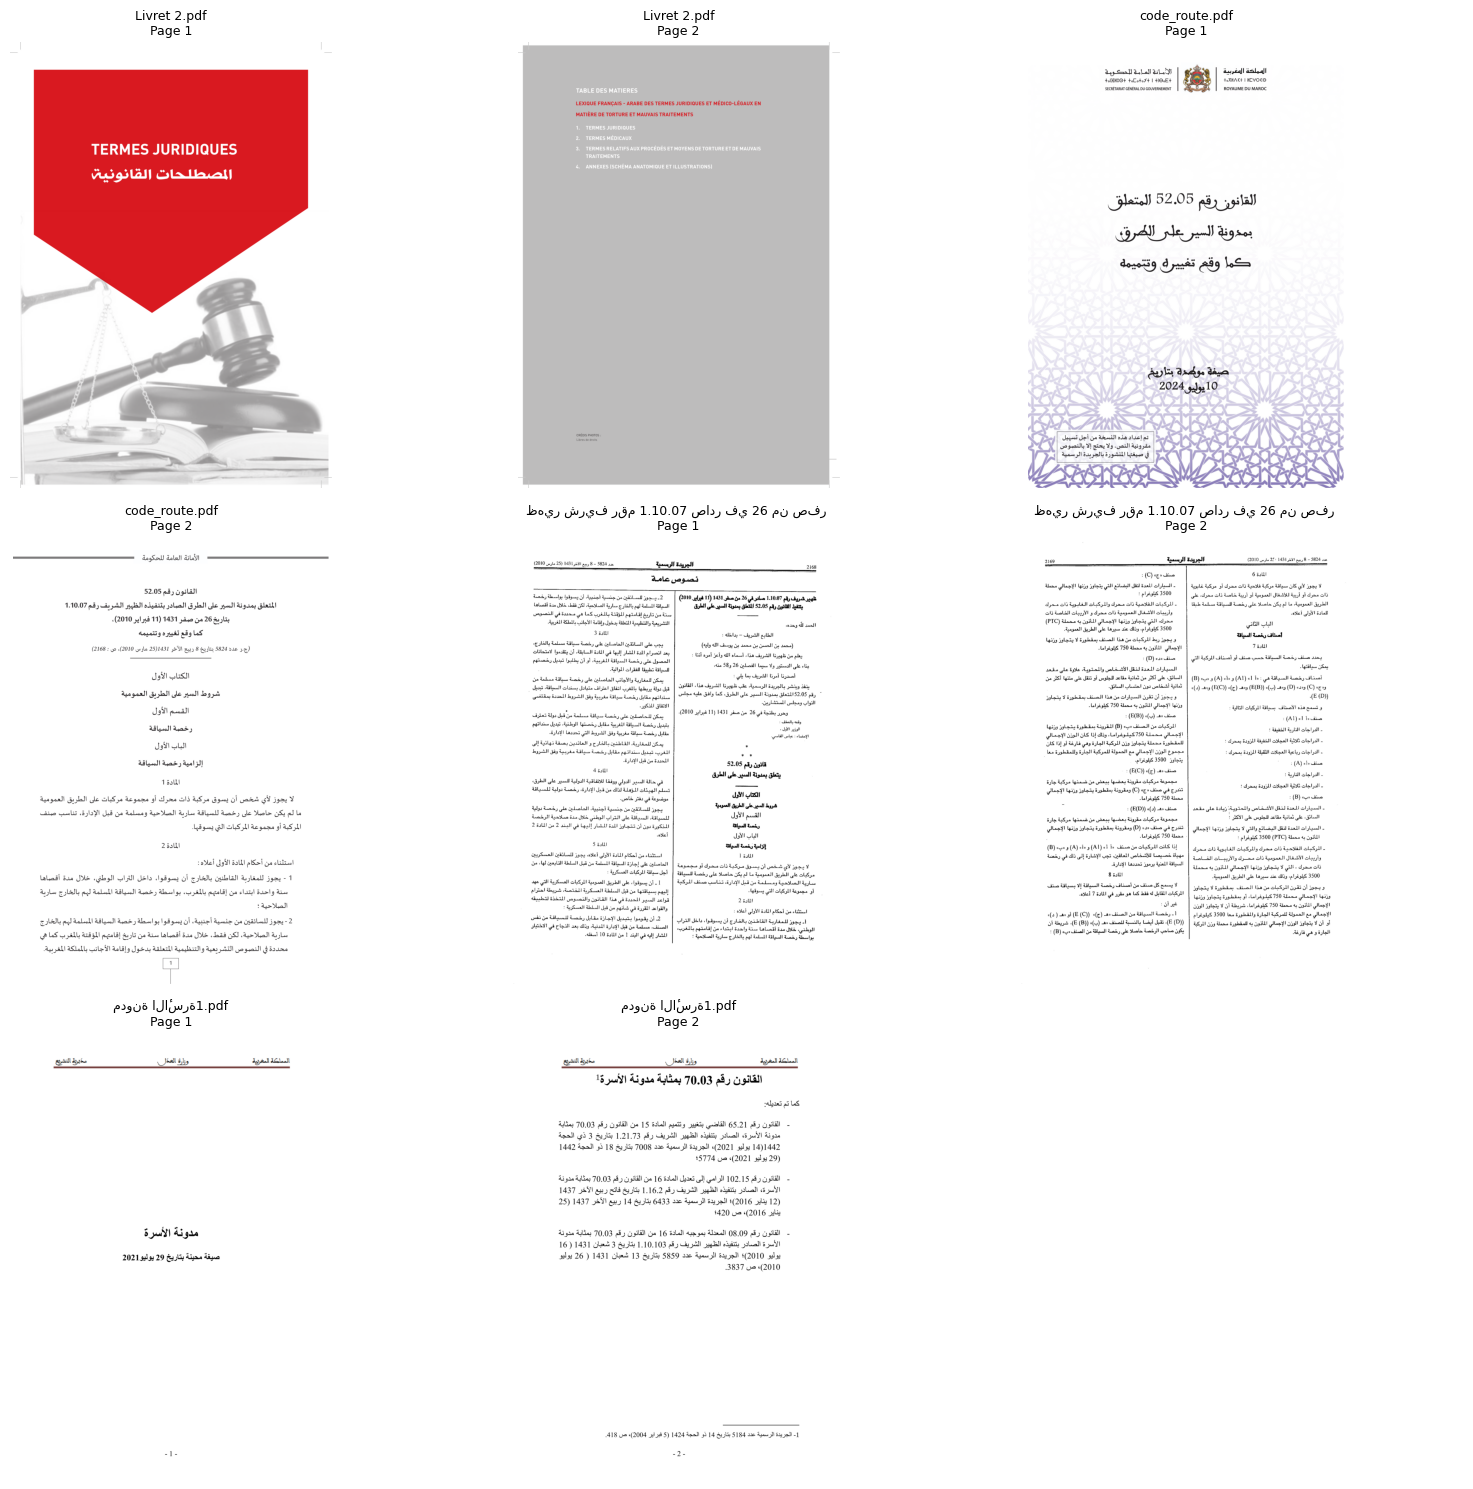

In [5]:
!apt-get install -y -qq poppler-utils

from pdf2image import convert_from_path
import matplotlib.pyplot as plt

test_pages = []

for pdf_path in pdf_files:
    print(f"Converting: {pdf_path.name}")
    images = convert_from_path(pdf_path, dpi=300, first_page=1, last_page=2)
    for i, img in enumerate(images):
        test_pages.append({
            "source": pdf_path.name,
            "page_num": i + 1,
            "image": img,
        })
    print(f"  {len(images)} pages")

print(f"\nTotal pages: {len(test_pages)}")

# Show all
n = len(test_pages)
cols = min(n, 3)
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(16, 5*rows))
if rows == 1 and cols == 1:
    axes = [axes]
axes = axes.flatten() if hasattr(axes, 'flatten') else axes

for i, page in enumerate(test_pages):
    axes[i].imshow(page["image"])
    axes[i].set_title(f"{page['source'][:40]}\nPage {page['page_num']}", fontsize=9)
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [6]:
import time

print("Loading EasyOCR Arabic reader...")
start = time.time()

reader = easyocr.Reader(lang_list=["ar","fa","ur","ug","en"], gpu=torch.cuda.is_available())

elapsed = time.time() - start
print(f"Reader ready in {elapsed:.1f}s")

Loading EasyOCR Arabic reader...
Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteReader ready in 9.1s


In [7]:
print("Running EasyOCR on all pages...")
print("=" * 60)

for i, page in enumerate(test_pages):
    img_array = np.array(page["image"])

    start = time.time()
    results = reader.readtext(img_array)
    elapsed = time.time() - start

    lines_text = [item[1] for item in results]
    text = "\n".join(lines_text)

    chars_total = len(text.strip())
    arabic = sum(1 for c in text if '\u0600' <= c <= '\u06ff')
    french = sum(1 for c in text if c.isascii() and c.isalpha())
    arabic_density = (arabic / chars_total * 100) if chars_total > 0 else 0

    # Confidence
    confidences = [item[2] for item in results]
    avg_conf = sum(confidences) / len(confidences) * 100 if confidences else 0

    page["easy_text"] = text.strip()
    page["easy_chars"] = chars_total
    page["easy_arabic"] = arabic
    page["easy_time"] = round(elapsed, 1)
    page["easy_lines"] = len(lines_text)
    page["easy_conf"] = round(avg_conf, 1)

    quality = "GOOD" if arabic > 500 else "LOW" if arabic < 100 else "MODERATE"

    print(f"[{quality}] {page['source'][:40]} p{page['page_num']}")
    print(f"       Chars: {chars_total} | Arabic: {arabic} ({arabic_density:.0f}%) | Conf: {avg_conf:.0f}% | Time: {elapsed:.1f}s")
    preview = text.strip()[:200].replace('\n', ' | ')
    print(f"       Preview: {preview}...")
    print()

print("=" * 60)
print("OCR complete.")

Running EasyOCR on all pages...
[LOW] Livret 2.pdf p1
       Chars: 38 | Arabic: 17 (45%) | Conf: 50% | Time: 2.1s
       Preview: TERMES JURIDIQUES | الصطلحات القانونية | ^...

[LOW] Livret 2.pdf p2
       Chars: 319 | Arabic: 0 (0%) | Conf: 76% | Time: 1.8s
       Preview: TABLE DES MATIERES | LEXIQUE FRANCAIS | ARABE DES TERMES JURIDIQUES ET MEDICO-LEGAUX EN | MATIERE DE TORTURE ET MAUVAIS TRAITEMENTS | 1 | TERMES JURIDIQUES | 2 | TERMES MEDICAUX | 3 | TERMES RELATIFS AUX PROCEDES ET MO...

[MODERATE] code_route.pdf p1
       Chars: 349 | Arabic: 201 (58%) | Conf: 54% | Time: 3.2s
       Preview: الأمانة العامة للحكومة | المملكة المغربية | +|]{M80+ +.[a+.>+ | +|O٤+ | +<^#Xہ+ | M[VO<O | SECRTARIAT GENERAL DU GOUVERNEMENT | ROYAUME DU MAROC | 52.05 | القانون رقم | السیر علی اللصرق | كما وقع تغييره وتتميمه | صيفة موصمة ...

[GOOD] code_route.pdf p2
       Chars: 1014 | Arabic: 790 (78%) | Conf: 73% | Time: 5.4s
       Preview: الأمانة العامة للحكومة | رقم 52.05 | على الطرق الصادر بتنفي

In [8]:
total_arabic = sum(p["easy_arabic"] for p in test_pages)
total_chars = sum(p["easy_chars"] for p in test_pages)
total_time = sum(p["easy_time"] for p in test_pages)
good_pages = sum(1 for p in test_pages if p["easy_arabic"] > 500)

print("=" * 60)
print("EASYOCR SUMMARY")
print("=" * 60)
print(f"Pages processed: {len(test_pages)}")
print(f"Good pages (>500 Arabic chars): {good_pages}")
print(f"Total characters: {total_chars}")
print(f"Total Arabic characters: {total_arabic}")
print(f"Arabic density: {total_arabic/total_chars*100:.0f}%" if total_chars > 0 else "N/A")
print(f"Total time: {total_time:.1f}s")
print(f"Average time per page: {total_time/len(test_pages):.1f}s")

print("\nPer-page breakdown:")
for i, p in enumerate(test_pages):
    print(f"  Page {i+1}: {p['easy_arabic']} Arabic chars, {p['easy_time']}s, {p['easy_lines']} lines, {p['easy_conf']}% conf")

EASYOCR SUMMARY
Pages processed: 8
Good pages (>500 Arabic chars): 4
Total characters: 8987
Total Arabic characters: 6430
Arabic density: 72%
Total time: 34.9s
Average time per page: 4.4s

Per-page breakdown:
  Page 1: 17 Arabic chars, 2.1s, 3 lines, 49.9% conf
  Page 2: 0 Arabic chars, 1.8s, 15 lines, 76.4% conf
  Page 3: 201 Arabic chars, 3.2s, 25 lines, 54.3% conf
  Page 4: 790 Arabic chars, 5.4s, 41 lines, 72.9% conf
  Page 5: 2443 Arabic chars, 8.6s, 164 lines, 70.2% conf
  Page 6: 2363 Arabic chars, 9.6s, 151 lines, 67.0% conf
  Page 7: 68 Arabic chars, 1.1s, 8 lines, 61.5% conf
  Page 8: 548 Arabic chars, 3.1s, 44 lines, 66.3% conf
